## 1 · Install & Imports

In [1]:
# If running on Google Colab and your data lives on Drive, mount it first:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q lightgbm xgboost catboost optuna scikit-learn pyarrow fastparquet tqdm scipy statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 14.9 MB/s eta 0:00:00


In [23]:
import warnings, os, time
warnings.filterwarnings('ignore')


import os
import re
import glob
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from datetime import datetime, timedelta

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.6f}'.format)
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

## 2 · Config

**Set `SYMBOL` and `HORIZON` here — this is the only cell you need to edit to re-run the
whole notebook for a different combo.**

In [15]:
# ── ⭐ THE TWO THINGS YOU CHANGE ⭐ ─────────────────────────────────────────
SYMBOL  = 'NIFTY50'     # one of: 'NIFTY50', 'BANKNIFTY', 'NIFTYNEXT50'  (edit freely)
HORIZON = 21            # one of: 1, 3, 5, 10, 21  (trading days ahead)

# ── Paths ─────────────────────────────────────────────────────────────────
# Adjust GDRIVE_BASE if your Phase-03 / Phase-04 outputs live somewhere else.
GDRIVE_BASE = '/content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107'

RUN_DATE = str((datetime.today() - timedelta(1)).strftime('%Y%m%d'))
RESULTS_DIR = os.path.join(GDRIVE_BASE, 'Models', f'Unified_{SYMBOL}_{HORIZON}_{RUN_DATE}', 'results')
print(RESULTS_DIR)

OUTPUT_DIR = os.path.join(GDRIVE_BASE,'Models', f'Unified_{SYMBOL}_{HORIZON}_{RUN_DATE}', "plots")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(OUTPUT_DIR)

/content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/results
/content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots


## 2 · Files and check

In [17]:
# Models to display, in desired order
MODEL_ORDER = [
    "Naive",
    "Linear_Logistic",
    "KNN",
    "SVM",
    "Random_Forest",
    "Gradient_Boosting",
    "MLP",
    "LightGBM_Tuned",
]


# ------------------------------------------------------------
# Metrics required for each layer
# ------------------------------------------------------------

LAYER_METRICS = {
    "L1": [
        "accuracy",
        "f1_macro",
    ],

    "L2": [
        "rmse",
        "mae",
        "directional_acc",
    ],

    "L3": [
        "rmse",
        "mae",
        "directional_acc",
    ],
}


# Human-readable names
METRIC_LABELS = {
    "accuracy": "Accuracy",
    "f1_macro": "F1 Macro",
    "rmse": "RMSE",
    "mae": "MAE",
    "directional_acc": "Directional Accuracy",
}


# Metrics where LOWER is better
LOWER_IS_BETTER = {
    "rmse",
    "mae",
}


# ============================================================
# 2. FIND ALL CSV FILES
# ============================================================

pattern = os.path.join(
    RESULTS_DIR,
    "leaderboard_*.csv"
)

files = sorted(glob.glob(pattern))

print(f"Found {len(files)} CSV files")

if not files:
    raise FileNotFoundError(
        f"No leaderboard CSV files found in:\n{RESULTS_DIR}"
    )

Found 30 CSV files


In [18]:
# ============================================================
# 3. READ ALL FILES
# ============================================================

all_dfs = []

for filepath in files:

    filename = os.path.basename(filepath)

    # --------------------------------------------------------
    # Extract layer
    # Example:
    # leaderboard_L1_NIFTY50_h21d_30features.csv
    # --------------------------------------------------------

    layer_match = re.search(
        r"leaderboard_(L\d+)_",
        filename,
        flags=re.IGNORECASE
    )

    if not layer_match:
        print(f"Skipping — layer not found: {filename}")
        continue

    layer = layer_match.group(1).upper()


    # --------------------------------------------------------
    # Extract feature count
    # --------------------------------------------------------

    feature_match = re.search(
        r"_(\d+)features\.csv$",
        filename,
        flags=re.IGNORECASE
    )

    if feature_match:
        n_features = int(feature_match.group(1))
    else:
        n_features = np.nan


    # --------------------------------------------------------
    # Read CSV
    # --------------------------------------------------------

    df = pd.read_csv(filepath)

    # Normalize column names
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
    )

    # Add metadata
    df["layer_file"] = layer
    df["n_features"] = n_features
    df["source_file"] = filename

    all_dfs.append(df)


# Combine everything
results = pd.concat(
    all_dfs,
    ignore_index=True
)


print("\nCombined shape:")
print(results.shape)

print("\nLayers:")
print(results["layer_file"].value_counts().sort_index())

print("\nFeature counts:")
print(
    sorted(
        results["n_features"]
        .dropna()
        .unique()
        .astype(int)
    )
)


Combined shape:
(2340, 25)

Layers:
layer_file
L1    780
L2    780
L3    780
Name: count, dtype: int64

Feature counts:
[np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70), np.int64(80), np.int64(90), np.int64(100), np.int64(110), np.int64(120)]


In [19]:
# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

print("\nColumns:")
print(results.columns.tolist())


required_base = {
    "model",
    "split",
}

missing_base = required_base - set(results.columns)

if missing_base:
    raise ValueError(
        f"Missing required columns: {missing_base}"
    )


# ============================================================
# 5. NORMALIZE SPLIT NAMES
# ============================================================

results["split"] = (
    results["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# We only want train and test
plot_results = results[
    results["split"].isin(["train", "test"])
].copy()


# ============================================================
# 6. NORMALIZE MODEL NAMES
# ============================================================

plot_results["model"] = (
    plot_results["model"]
    .astype(str)
    .str.strip()
)


Columns:
['layer', 'model', 'symbol', 'horizon', 'split', 'n', 'accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'cohen_kappa', 'mcc', 'roc_auc_ovr', 'log_loss', 'layer_file', 'n_features', 'source_file', 'rmse', 'mae', 'r2', 'adjusted_r2', 'mape', 'spearman_corr', 'directional_acc']


In [20]:
# ============================================================
# 7. HELPER — MODEL ORDER
# ============================================================

def sort_models(df):

    present_models = df["model"].unique().tolist()

    ordered = [
        model
        for model in MODEL_ORDER
        if model in present_models
    ]

    # Include any unexpected models at the end
    extras = [
        model
        for model in present_models
        if model not in ordered
    ]

    return ordered + sorted(extras)

In [21]:
# ============================================================
# 8. CREATE INDIVIDUAL PLOTS
# ============================================================

generated_files = []


for layer in ["L1", "L2", "L3"]:

    layer_df = plot_results[
        plot_results["layer_file"] == layer
    ].copy()

    if layer_df.empty:
        print(f"\nNo data for {layer}")
        continue


    # Feature counts available in this layer
    feature_counts = sorted(
        layer_df["n_features"]
        .dropna()
        .unique()
        .astype(int)
    )


    for n_features in feature_counts:

        feature_df = layer_df[
            layer_df["n_features"] == n_features
        ].copy()


        models = sort_models(feature_df)

        if not models:
            continue


        # ----------------------------------------------------
        # Create one figure per metric
        # ----------------------------------------------------

        for metric in LAYER_METRICS[layer]:

            if metric not in feature_df.columns:
                print(
                    f"WARNING: {metric} not found "
                    f"for {layer}, {n_features} features"
                )
                continue


            # Convert metric to numeric
            feature_df[metric] = pd.to_numeric(
                feature_df[metric],
                errors="coerce"
            )


            # ------------------------------------------------
            # Pivot
            # ------------------------------------------------

            pivot = (
                feature_df
                .pivot_table(
                    index="model",
                    columns="split",
                    values=metric,
                    aggfunc="first"
                )
                .reindex(models)
            )


            # ------------------------------------------------
            # Plot
            # ------------------------------------------------

            fig, ax = plt.subplots(
                figsize=(13, 7)
            )

            x = np.arange(len(models))

            width = 0.38


            train_values = (
                pivot["train"]
                if "train" in pivot.columns
                else np.full(len(models), np.nan)
            )

            test_values = (
                pivot["test"]
                if "test" in pivot.columns
                else np.full(len(models), np.nan)
            )


            bars_train = ax.bar(
                x - width / 2,
                train_values,
                width,
                label="Train"
            )

            bars_test = ax.bar(
                x + width / 2,
                test_values,
                width,
                label="Test"
            )


            # ------------------------------------------------
            # Formatting
            # ------------------------------------------------

            metric_label = METRIC_LABELS.get(
                metric,
                metric.replace("_", " ").title()
            )


            ax.set_title(
                f"NIFTY50 — {layer} — "
                f"{metric_label} — "
                f"{n_features} Features",
                fontsize=15,
                fontweight="bold"
            )


            ax.set_xlabel(
                "Model",
                fontsize=12
            )

            ax.set_ylabel(
                metric_label,
                fontsize=12
            )


            ax.set_xticks(x)

            ax.set_xticklabels(
                models,
                rotation=30,
                ha="right"
            )


            ax.legend(
                loc="best"
            )


            ax.grid(
                axis="y",
                alpha=0.25
            )


            # ------------------------------------------------
            # Scale
            # ------------------------------------------------

            if metric in LOWER_IS_BETTER:

                # Useful because some train RMSE/MAE values
                # may be extremely close to zero.
                positive_values = np.concatenate([
                    train_values[np.isfinite(train_values) & (train_values > 0)],
                    test_values[np.isfinite(test_values) & (test_values > 0)]
                ])

                if len(positive_values) > 0:
                    ax.set_yscale("log")


            elif metric in {
                "accuracy",
                "f1_macro",
                "directional_acc"
            }:

                ax.set_ylim(
                    0,
                    1.05
                )


            # ------------------------------------------------
            # Value labels
            # ------------------------------------------------

            def add_labels(bars):

                for bar in bars:

                    height = bar.get_height()

                    if not np.isfinite(height):
                        continue

                    if metric in LOWER_IS_BETTER:

                        text = f"{height:.4g}"

                    else:

                        text = f"{height:.3f}"


                    ax.annotate(
                        text,
                        xy=(
                            bar.get_x() +
                            bar.get_width() / 2,
                            height
                        ),
                        xytext=(0, 4),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=8,
                        rotation=90
                    )


            add_labels(bars_train)
            add_labels(bars_test)


            fig.tight_layout()


            # ------------------------------------------------
            # Save
            # ------------------------------------------------

            output_file = os.path.join(
                OUTPUT_DIR,
                f"{layer}_{n_features}features_{metric}.png"
            )

            fig.savefig(
                output_file,
                dpi=200,
                bbox_inches="tight"
            )

            plt.close(fig)

            generated_files.append(output_file)


            print(
                f"Created: "
                f"{layer} | "
                f"{n_features} features | "
                f"{metric}"
            )


print(
    f"\nGenerated {len(generated_files)} plots."
)

print(
    f"Output directory:\n{OUTPUT_DIR}"
)

Created: L1 | 30 features | accuracy
Created: L1 | 30 features | f1_macro
Created: L1 | 40 features | accuracy
Created: L1 | 40 features | f1_macro
Created: L1 | 50 features | accuracy
Created: L1 | 50 features | f1_macro
Created: L1 | 60 features | accuracy
Created: L1 | 60 features | f1_macro
Created: L1 | 70 features | accuracy
Created: L1 | 70 features | f1_macro
Created: L1 | 80 features | accuracy
Created: L1 | 80 features | f1_macro
Created: L1 | 90 features | accuracy
Created: L1 | 90 features | f1_macro
Created: L1 | 100 features | accuracy
Created: L1 | 100 features | f1_macro
Created: L1 | 110 features | accuracy
Created: L1 | 110 features | f1_macro
Created: L1 | 120 features | accuracy
Created: L1 | 120 features | f1_macro
Created: L2 | 30 features | rmse
Created: L2 | 30 features | mae
Created: L2 | 30 features | directional_acc
Created: L2 | 40 features | rmse
Created: L2 | 40 features | mae
Created: L2 | 40 features | directional_acc
Created: L2 | 50 features | rmse
Cre

Found 10 L1 files
Feature counts: [np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70), np.int64(80), np.int64(90), np.int64(100), np.int64(110), np.int64(120)]
Models: ['Naive', 'Linear_Logistic', 'KNN', 'SVM', 'Random_Forest', 'Gradient_Boosting', 'MLP', 'LightGBM_Tuned']


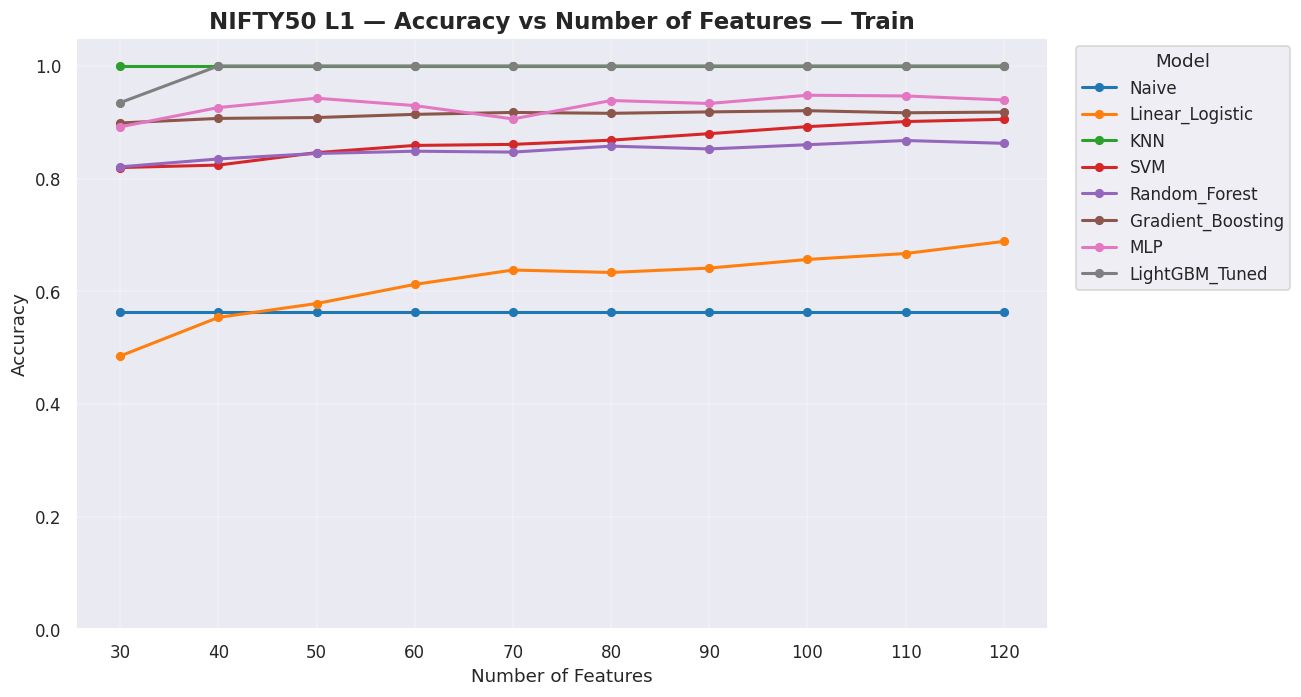

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/accuracy_train.png


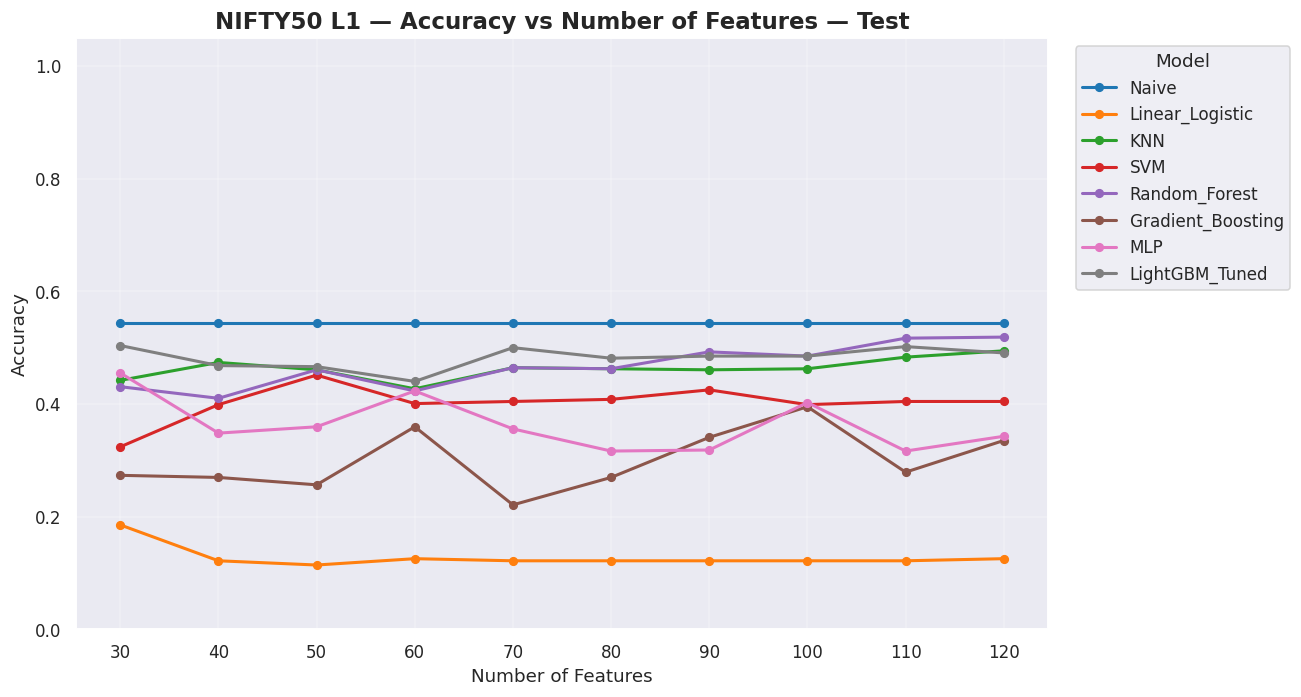

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/accuracy_test.png


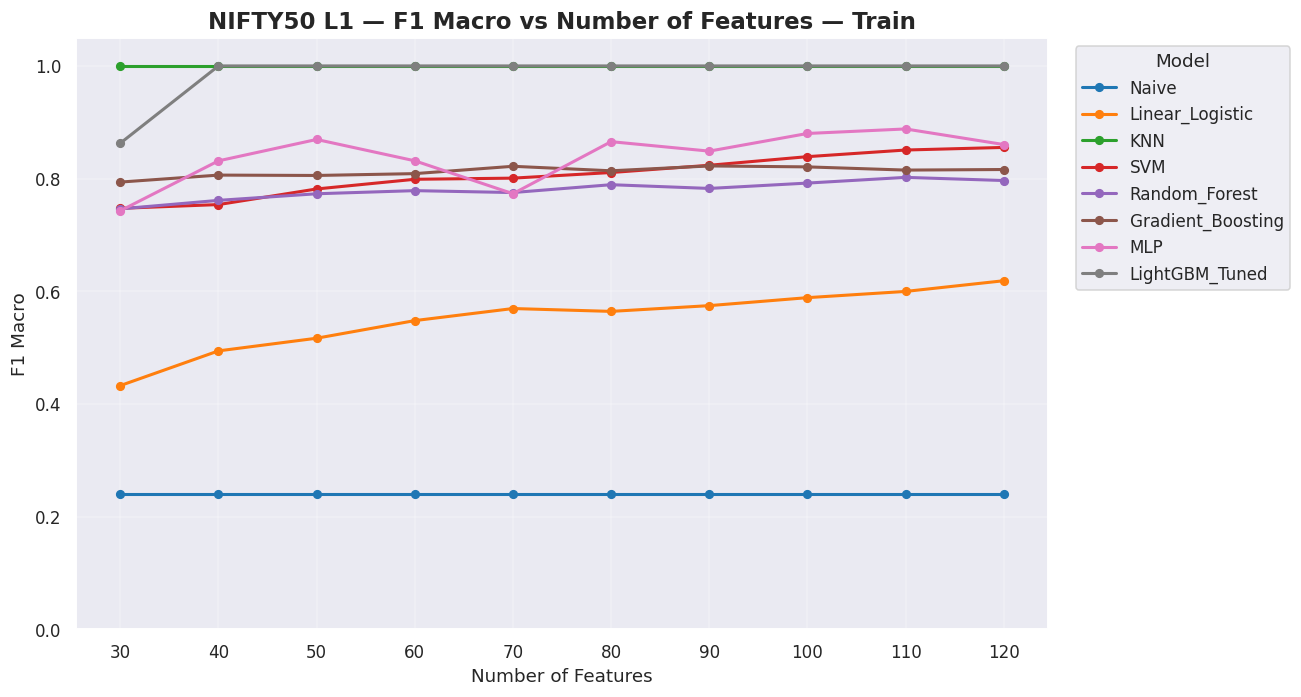

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/f1_macro_train.png


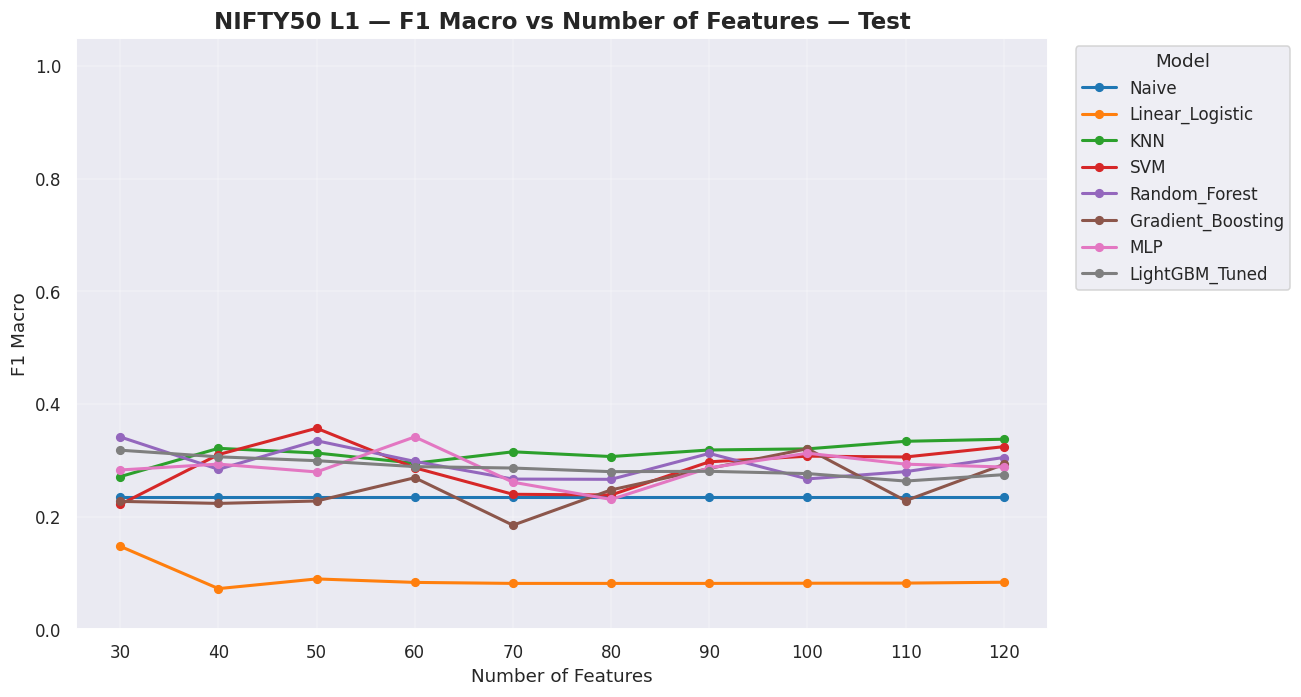

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/f1_macro_test.png


In [25]:
# ============================================================
# MODELS
# ============================================================

MODELS = [
    "Naive",
    "Linear_Logistic",
    "KNN",
    "SVM",
    "Random_Forest",
    "Gradient_Boosting",
    "MLP",
    "LightGBM_Tuned",
]


# ============================================================
# READ ALL L1 FILES
# ============================================================

files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "leaderboard_L1_NIFTY50_h21d_*features.csv"
        )
    )
)

print(f"Found {len(files)} L1 files")


dfs = []

for filepath in files:

    filename = os.path.basename(filepath)

    match = re.search(
        r"_(\d+)features\.csv$",
        filename
    )

    if not match:
        continue

    n_features = int(match.group(1))

    df = pd.read_csv(filepath)

    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
    )

    df["n_features"] = n_features

    dfs.append(df)


if not dfs:
    raise ValueError("No L1 data found.")


l1 = pd.concat(
    dfs,
    ignore_index=True
)


# ============================================================
# CLEAN
# ============================================================

l1["split"] = (
    l1["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

l1["model"] = (
    l1["model"]
    .astype(str)
    .str.strip()
)


# ONLY TRAIN / TEST
l1 = l1[
    l1["split"].isin(
        ["train", "test"]
    )
].copy()


# ONLY OUR 8 MODELS
l1 = l1[
    l1["model"].isin(MODELS)
].copy()


feature_counts = sorted(
    l1["n_features"].unique()
)


print("Feature counts:", feature_counts)
print("Models:", MODELS)


# ============================================================
# MODEL COLORS
# ============================================================

cmap = plt.get_cmap("tab10")

MODEL_COLORS = {
    model: cmap(i)
    for i, model in enumerate(MODELS)
}


# ============================================================
# PLOT FUNCTION
# ============================================================

def plot_metric_split(
    df,
    metric,
    split,
    title,
    ylabel
):

    fig, ax = plt.subplots(
        figsize=(12, 6.5)
    )


    # --------------------------------------------------------
    # Plot every model
    # --------------------------------------------------------

    for model in MODELS:

        tmp = df[
            (df["model"] == model) &
            (df["split"] == split)
        ].copy()


        if tmp.empty:
            continue


        tmp = tmp.sort_values(
            "n_features"
        )


        values = pd.to_numeric(
            tmp[metric],
            errors="coerce"
        )


        ax.plot(
            tmp["n_features"],
            values,
            color=MODEL_COLORS[model],
            marker="o",
            linewidth=2,
            markersize=5,
            label=model
        )


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Number of Features",
        fontsize=12
    )

    ax.set_ylabel(
        ylabel,
        fontsize=12
    )

    ax.set_xticks(
        feature_counts
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.grid(
        True,
        alpha=0.25
    )


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        title="Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )


    fig.tight_layout()


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    output_file = os.path.join(
        OUTPUT_DIR,
        f"{metric}_{split}.png"
    )

    fig.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )


    # --------------------------------------------------------
    # SHOW IN NOTEBOOK
    # --------------------------------------------------------

    plt.show()


    print(
        f"Saved: {output_file}"
    )


# ============================================================
# 1. ACCURACY — TRAIN
# ============================================================

plot_metric_split(
    l1,
    "accuracy",
    "train",
    "NIFTY50 L1 — Accuracy vs Number of Features — Train",
    "Accuracy"
)


# ============================================================
# 2. ACCURACY — TEST
# ============================================================

plot_metric_split(
    l1,
    "accuracy",
    "test",
    "NIFTY50 L1 — Accuracy vs Number of Features — Test",
    "Accuracy"
)


# ============================================================
# 3. F1 MACRO — TRAIN
# ============================================================

plot_metric_split(
    l1,
    "f1_macro",
    "train",
    "NIFTY50 L1 — F1 Macro vs Number of Features — Train",
    "F1 Macro"
)


# ============================================================
# 4. F1 MACRO — TEST
# ============================================================

plot_metric_split(
    l1,
    "f1_macro",
    "test",
    "NIFTY50 L1 — F1 Macro vs Number of Features — Test",
    "F1 Macro"
)

Found 10 L2 files
Feature counts: [np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70), np.int64(80), np.int64(90), np.int64(100), np.int64(110), np.int64(120)]
Models: ['Naive', 'Linear_Logistic', 'KNN', 'SVM', 'Random_Forest', 'Gradient_Boosting', 'MLP', 'LightGBM_Tuned']


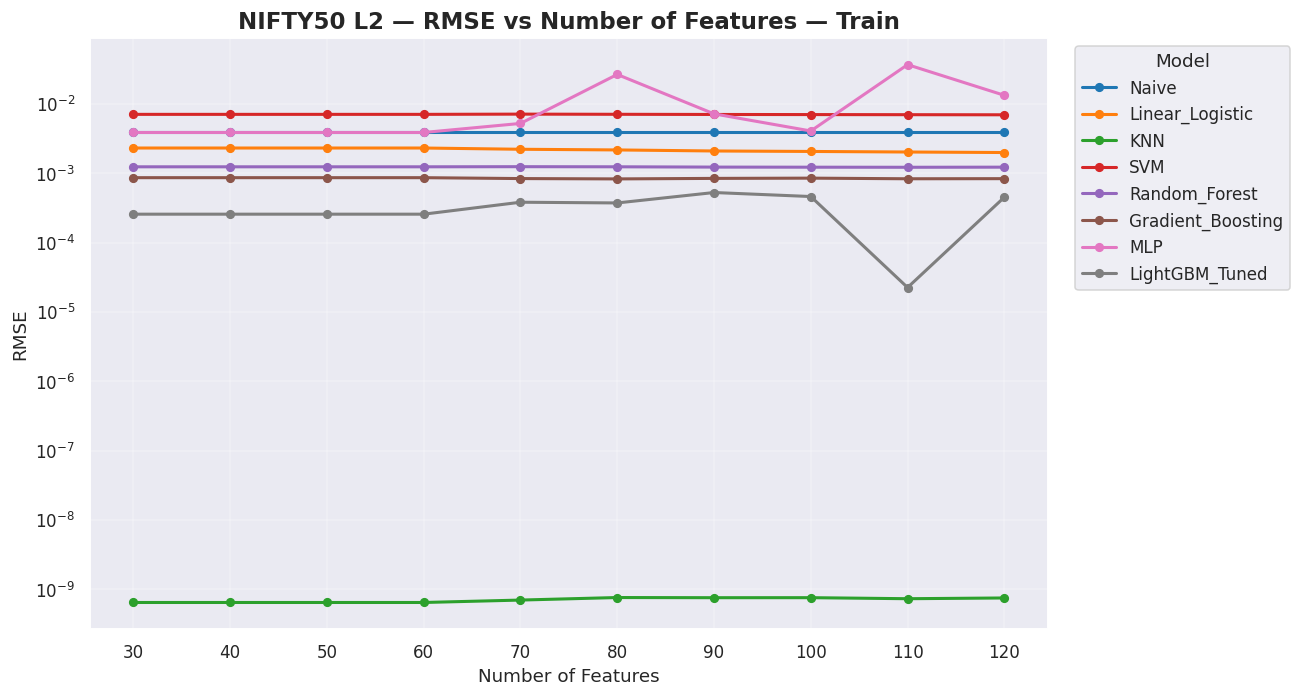

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/rmse_train.png


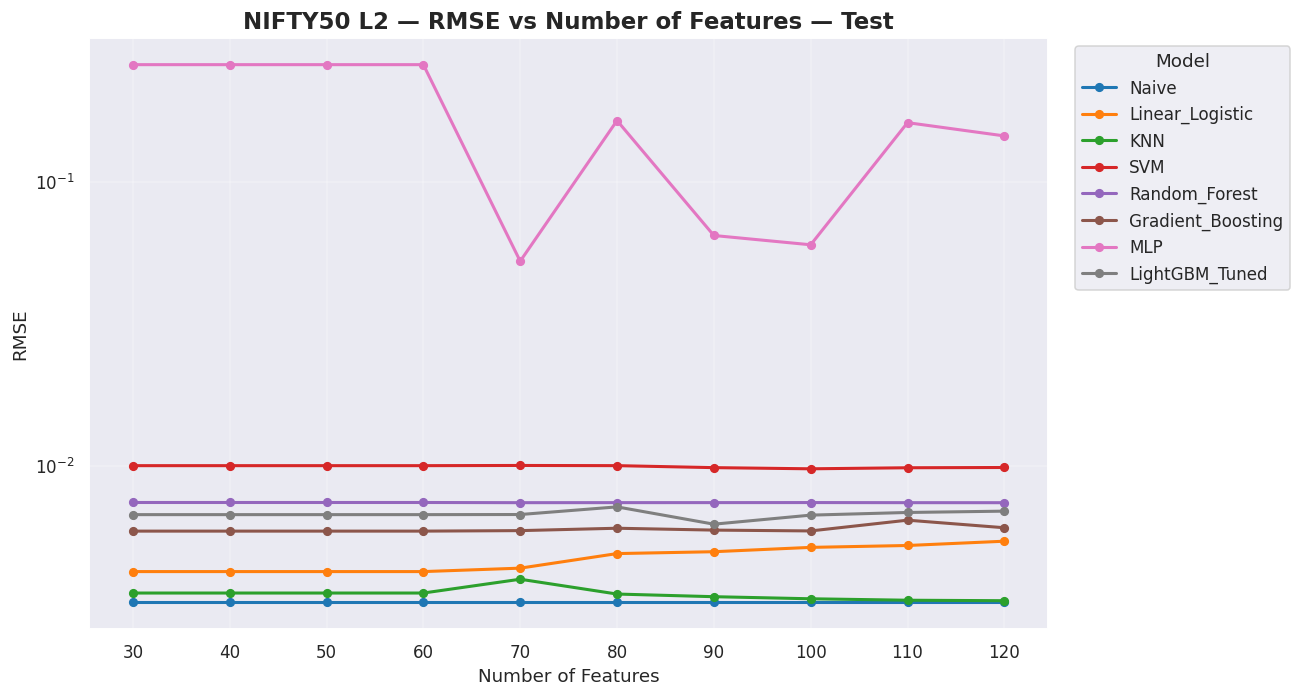

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/rmse_test.png


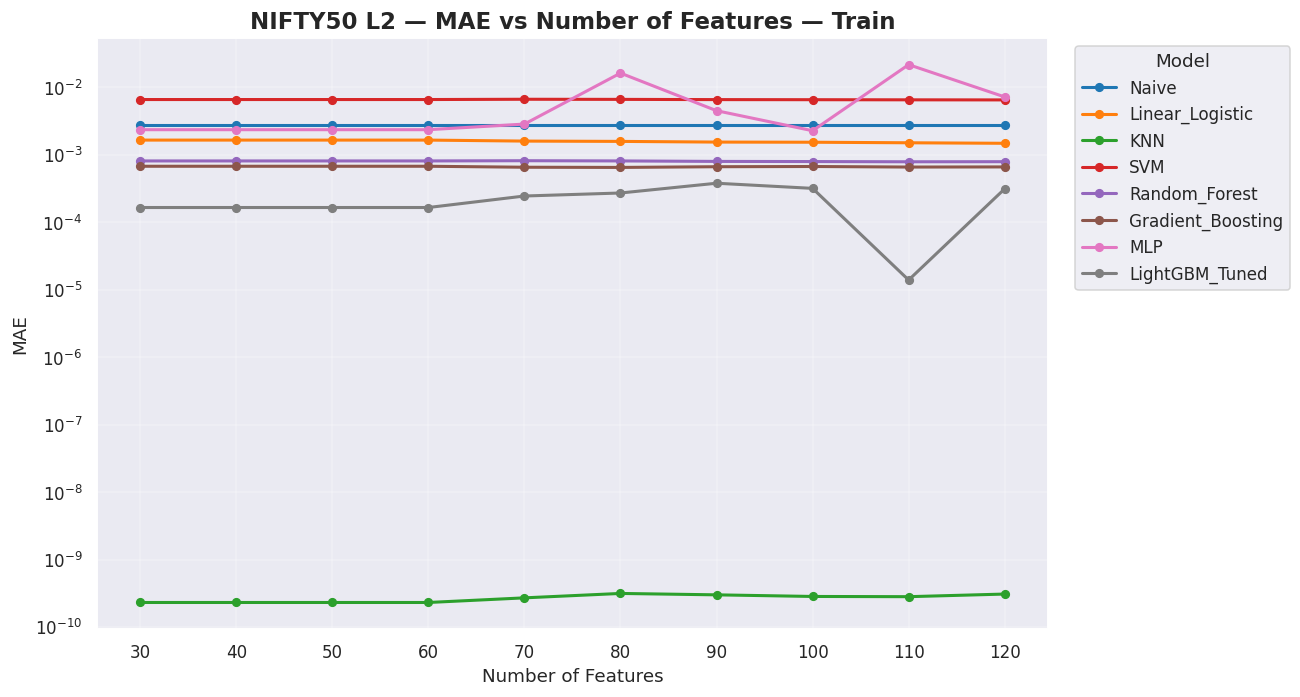

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/mae_train.png


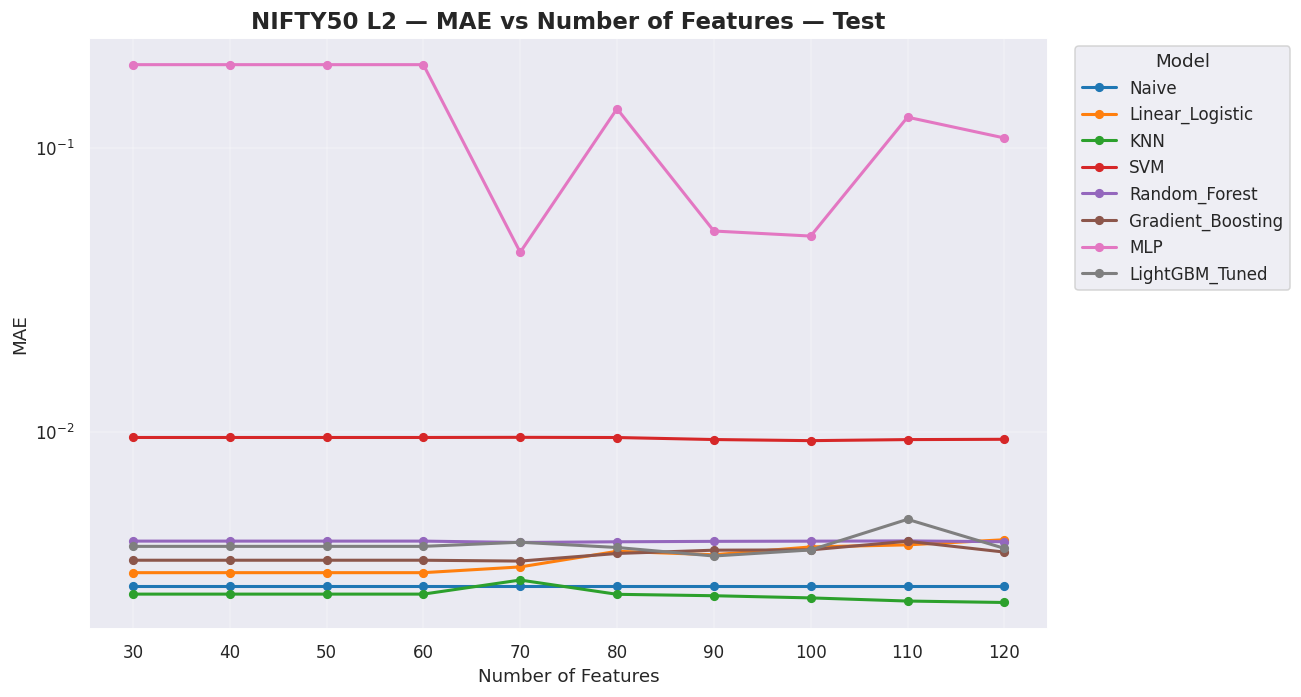

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/mae_test.png


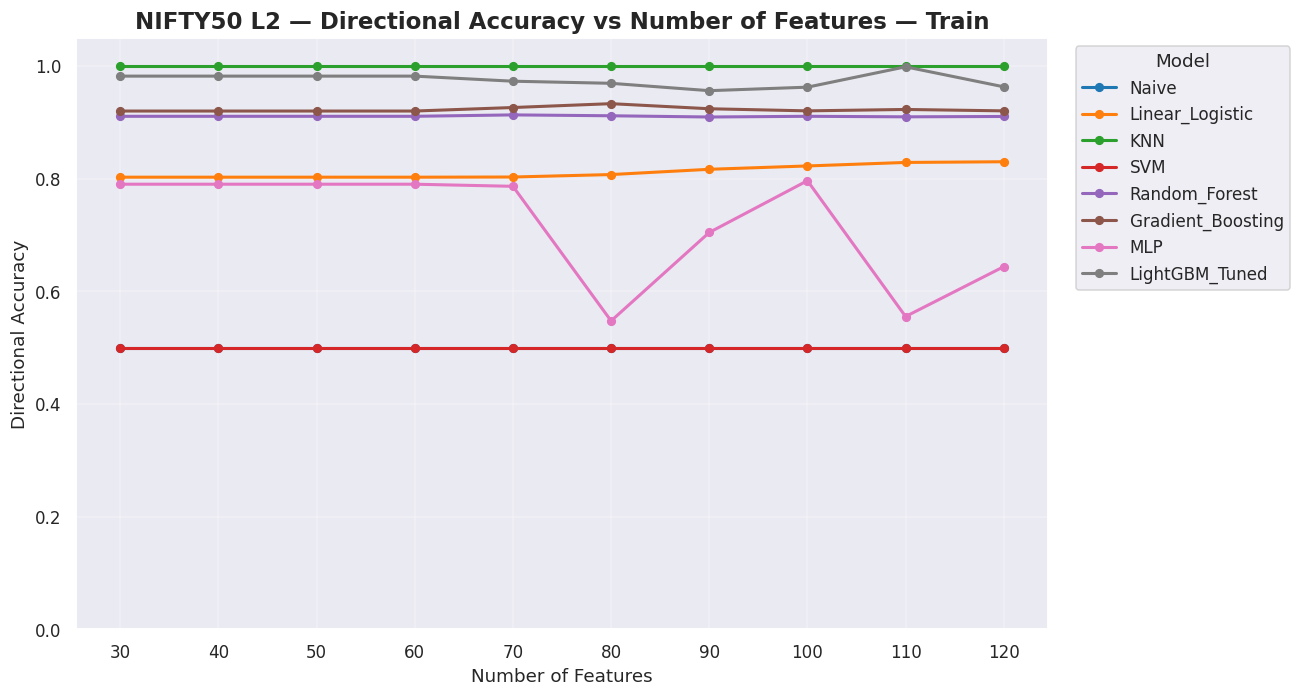

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/directional_acc_train.png


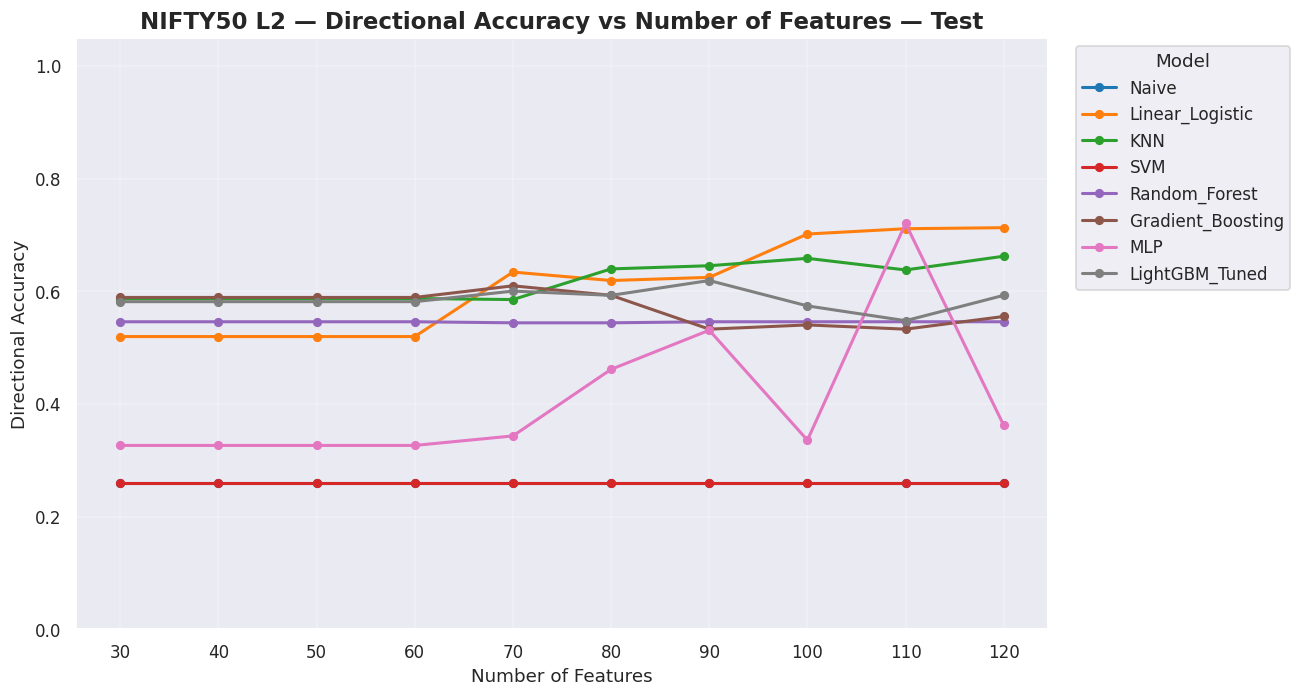

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/directional_acc_test.png


In [26]:
# ============================================================
# MODELS
# ============================================================

MODELS = [
    "Naive",
    "Linear_Logistic",
    "KNN",
    "SVM",
    "Random_Forest",
    "Gradient_Boosting",
    "MLP",
    "LightGBM_Tuned",
]


# ============================================================
# READ FILES
# ============================================================

files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "leaderboard_L2_NIFTY50_h21d_*features.csv"
        )
    )
)

print(f"Found {len(files)} L2 files")


dfs = []

for filepath in files:

    filename = os.path.basename(filepath)

    match = re.search(
        r"_(\d+)features\.csv$",
        filename
    )

    if not match:
        continue

    n_features = int(match.group(1))

    df = pd.read_csv(filepath)

    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
    )

    df["n_features"] = n_features

    dfs.append(df)


if not dfs:
    raise ValueError("No L2 data found.")


l2 = pd.concat(
    dfs,
    ignore_index=True
)


# ============================================================
# CLEAN
# ============================================================

l2["split"] = (
    l2["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

l2["model"] = (
    l2["model"]
    .astype(str)
    .str.strip()
)


l2 = l2[
    l2["split"].isin(
        ["train", "test"]
    )
].copy()


l2 = l2[
    l2["model"].isin(MODELS)
].copy()


feature_counts = sorted(
    l2["n_features"].unique()
)


print("Feature counts:", feature_counts)
print("Models:", MODELS)


# ============================================================
# MODEL COLORS
# ============================================================

cmap = plt.get_cmap("tab10")

MODEL_COLORS = {
    model: cmap(i)
    for i, model in enumerate(MODELS)
}


# ============================================================
# GENERIC PLOT FUNCTION
# ============================================================

def plot_metric_split(
    df,
    metric,
    split,
    title,
    ylabel,
    log_scale=False
):

    fig, ax = plt.subplots(
        figsize=(12, 6.5)
    )


    for model in MODELS:

        tmp = df[
            (df["model"] == model) &
            (df["split"] == split)
        ].copy()


        if tmp.empty:
            continue


        tmp = tmp.sort_values(
            "n_features"
        )


        values = pd.to_numeric(
            tmp[metric],
            errors="coerce"
        )


        ax.plot(
            tmp["n_features"],
            values,
            color=MODEL_COLORS[model],
            marker="o",
            linewidth=2,
            markersize=5,
            label=model
        )


    # --------------------------------------------------------
    # Axis
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Number of Features",
        fontsize=12
    )

    ax.set_ylabel(
        ylabel,
        fontsize=12
    )

    ax.set_xticks(
        feature_counts
    )


    # --------------------------------------------------------
    # Log scale for error metrics
    # --------------------------------------------------------

    if log_scale:

        ax.set_yscale(
            "log"
        )


    # --------------------------------------------------------
    # Directional accuracy
    # --------------------------------------------------------

    if metric == "directional_acc":

        ax.set_ylim(
            0,
            1.05
        )


    ax.grid(
        True,
        alpha=0.25
    )


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        title="Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )


    fig.tight_layout()


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    output_file = os.path.join(
        OUTPUT_DIR,
        f"{metric}_{split}.png"
    )

    fig.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )


    # --------------------------------------------------------
    # Notebook display
    # --------------------------------------------------------

    plt.show()


    print(
        f"Saved: {output_file}"
    )


# ============================================================
# 1. RMSE — TRAIN
# ============================================================

plot_metric_split(
    l2,
    "rmse",
    "train",
    "NIFTY50 L2 — RMSE vs Number of Features — Train",
    "RMSE",
    log_scale=True
)


# ============================================================
# 2. RMSE — TEST
# ============================================================

plot_metric_split(
    l2,
    "rmse",
    "test",
    "NIFTY50 L2 — RMSE vs Number of Features — Test",
    "RMSE",
    log_scale=True
)


# ============================================================
# 3. MAE — TRAIN
# ============================================================

plot_metric_split(
    l2,
    "mae",
    "train",
    "NIFTY50 L2 — MAE vs Number of Features — Train",
    "MAE",
    log_scale=True
)


# ============================================================
# 4. MAE — TEST
# ============================================================

plot_metric_split(
    l2,
    "mae",
    "test",
    "NIFTY50 L2 — MAE vs Number of Features — Test",
    "MAE",
    log_scale=True
)


# ============================================================
# 5. DIRECTIONAL ACCURACY — TRAIN
# ============================================================

plot_metric_split(
    l2,
    "directional_acc",
    "train",
    "NIFTY50 L2 — Directional Accuracy vs Number of Features — Train",
    "Directional Accuracy"
)


# ============================================================
# 6. DIRECTIONAL ACCURACY — TEST
# ============================================================

plot_metric_split(
    l2,
    "directional_acc",
    "test",
    "NIFTY50 L2 — Directional Accuracy vs Number of Features — Test",
    "Directional Accuracy"
)

Found 10 L3 files
Feature counts: [np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70), np.int64(80), np.int64(90), np.int64(100), np.int64(110), np.int64(120)]
Models: ['Naive', 'Linear_Logistic', 'KNN', 'SVM', 'Random_Forest', 'Gradient_Boosting', 'MLP', 'LightGBM_Tuned']


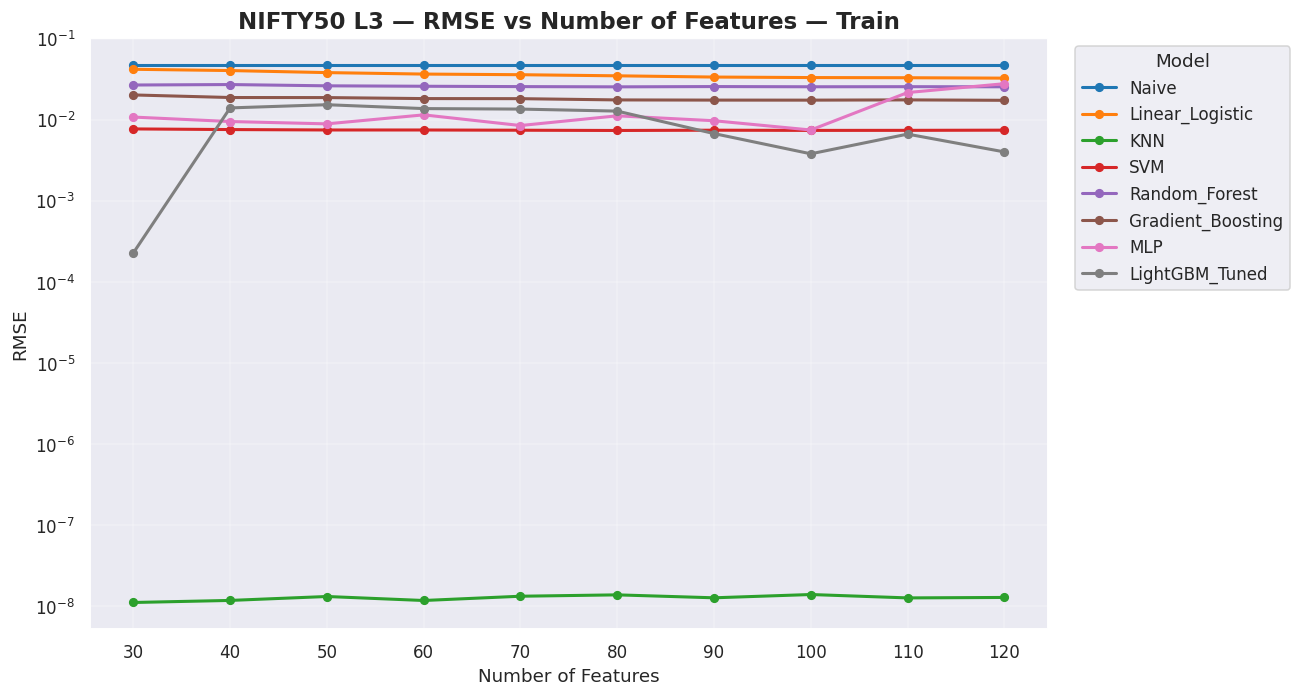

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/rmse_train.png


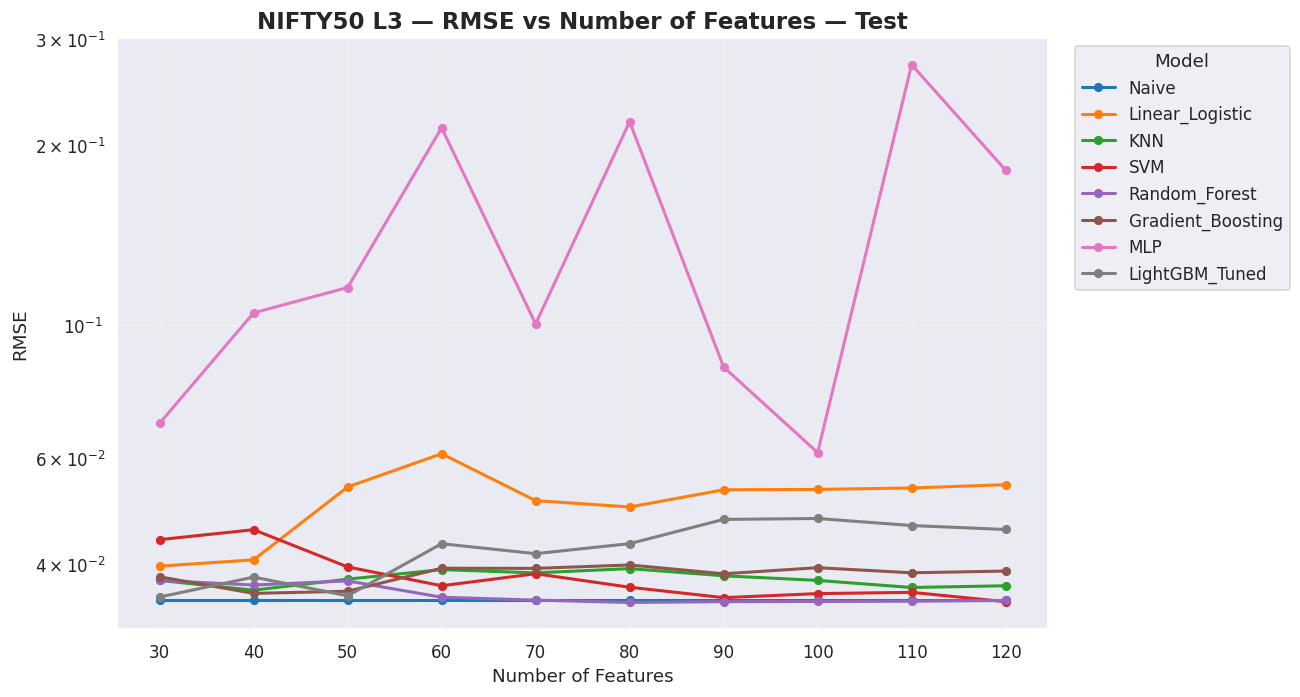

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/rmse_test.png


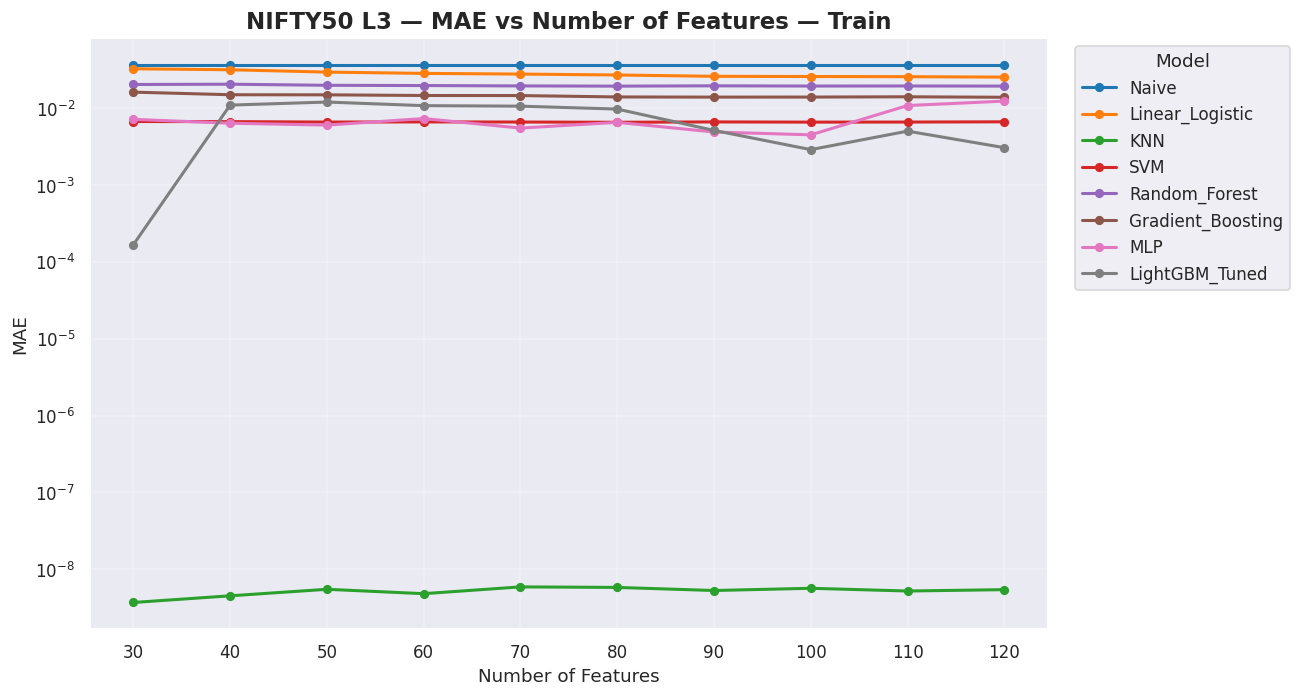

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/mae_train.png


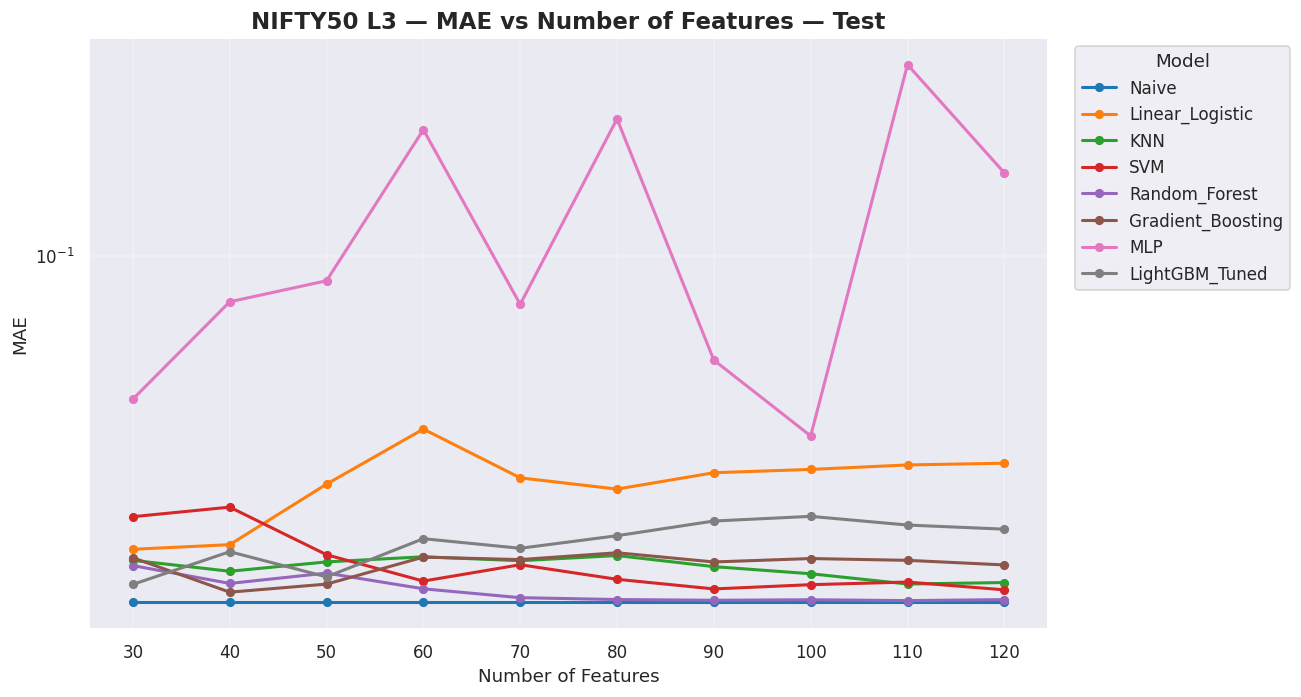

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/mae_test.png


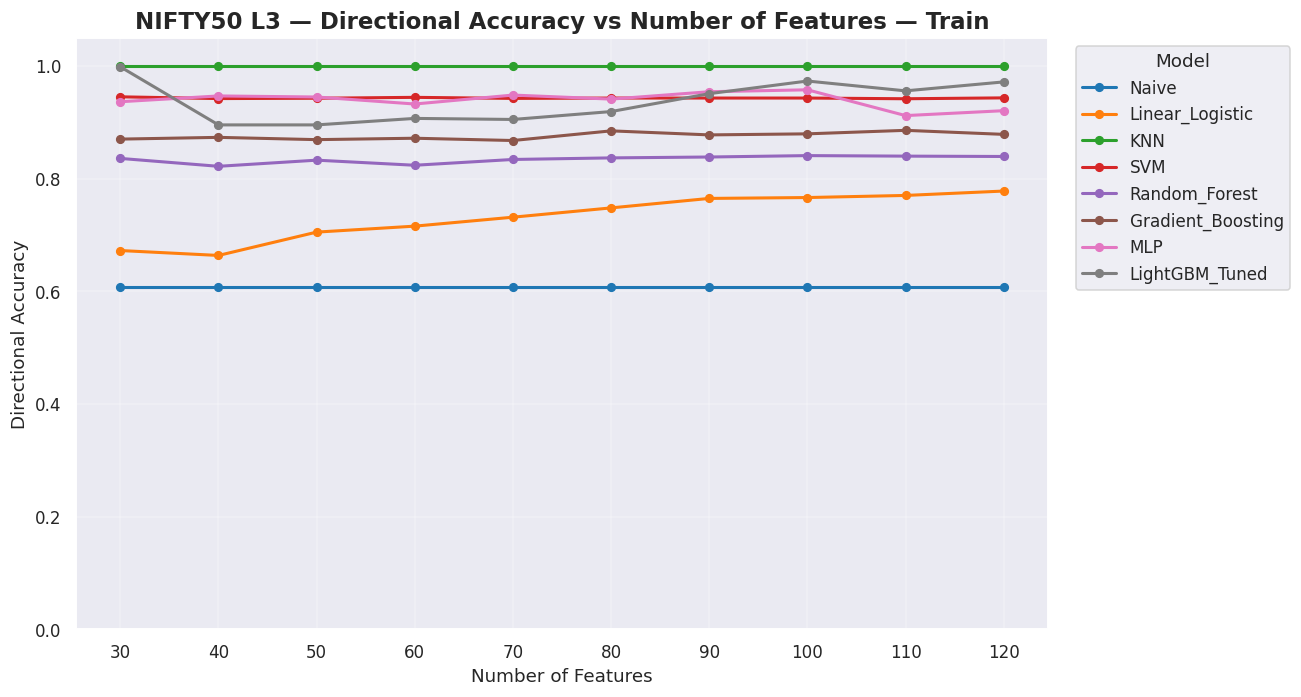

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/directional_acc_train.png


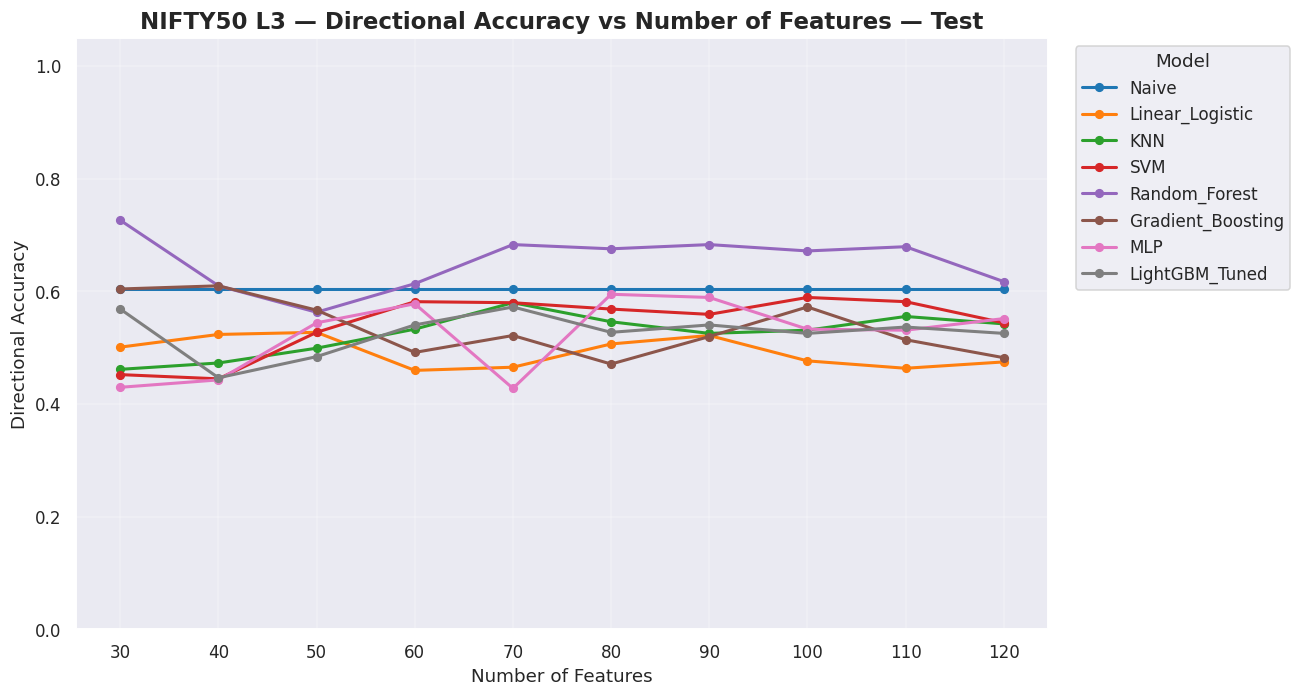

Saved: /content/drive/MyDrive/Regime_Detection_Swagato_M25AI2107/Models/Unified_NIFTY50_21_20260831/plots/directional_acc_test.png


In [27]:
# ============================================================
# MODELS
# ============================================================

MODELS = [
    "Naive",
    "Linear_Logistic",
    "KNN",
    "SVM",
    "Random_Forest",
    "Gradient_Boosting",
    "MLP",
    "LightGBM_Tuned",
]


# ============================================================
# READ FILES
# ============================================================

files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "leaderboard_L3_NIFTY50_h21d_*features.csv"
        )
    )
)

print(f"Found {len(files)} L3 files")


dfs = []

for filepath in files:

    filename = os.path.basename(filepath)

    match = re.search(
        r"_(\d+)features\.csv$",
        filename
    )

    if not match:
        continue

    n_features = int(match.group(1))

    df = pd.read_csv(filepath)

    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
    )

    df["n_features"] = n_features

    dfs.append(df)


if not dfs:
    raise ValueError("No L3 data found.")


l3 = pd.concat(
    dfs,
    ignore_index=True
)


# ============================================================
# CLEAN
# ============================================================

l3["split"] = (
    l3["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

l3["model"] = (
    l3["model"]
    .astype(str)
    .str.strip()
)


l3 = l3[
    l3["split"].isin(
        ["train", "test"]
    )
].copy()


l3 = l3[
    l3["model"].isin(MODELS)
].copy()


feature_counts = sorted(
    l3["n_features"].unique()
)


print("Feature counts:", feature_counts)
print("Models:", MODELS)


# ============================================================
# MODEL COLORS
# ============================================================

cmap = plt.get_cmap("tab10")

MODEL_COLORS = {
    model: cmap(i)
    for i, model in enumerate(MODELS)
}


# ============================================================
# GENERIC PLOT FUNCTION
# ============================================================

def plot_metric_split(
    df,
    metric,
    split,
    title,
    ylabel,
    log_scale=False
):

    fig, ax = plt.subplots(
        figsize=(12, 6.5)
    )


    for model in MODELS:

        tmp = df[
            (df["model"] == model) &
            (df["split"] == split)
        ].copy()


        if tmp.empty:
            continue


        tmp = tmp.sort_values(
            "n_features"
        )


        values = pd.to_numeric(
            tmp[metric],
            errors="coerce"
        )


        ax.plot(
            tmp["n_features"],
            values,
            color=MODEL_COLORS[model],
            marker="o",
            linewidth=2,
            markersize=5,
            label=model
        )


    # --------------------------------------------------------
    # Axis
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Number of Features",
        fontsize=12
    )

    ax.set_ylabel(
        ylabel,
        fontsize=12
    )

    ax.set_xticks(
        feature_counts
    )


    # --------------------------------------------------------
    # Scale
    # --------------------------------------------------------

    if log_scale:

        ax.set_yscale(
            "log"
        )


    if metric == "directional_acc":

        ax.set_ylim(
            0,
            1.05
        )


    ax.grid(
        True,
        alpha=0.25
    )


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        title="Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )


    fig.tight_layout()


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    output_file = os.path.join(
        OUTPUT_DIR,
        f"{metric}_{split}.png"
    )


    fig.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )


    # --------------------------------------------------------
    # Display in notebook
    # --------------------------------------------------------

    plt.show()


    print(
        f"Saved: {output_file}"
    )


# ============================================================
# 1. RMSE — TRAIN
# ============================================================

plot_metric_split(
    l3,
    "rmse",
    "train",
    "NIFTY50 L3 — RMSE vs Number of Features — Train",
    "RMSE",
    log_scale=True
)


# ============================================================
# 2. RMSE — TEST
# ============================================================

plot_metric_split(
    l3,
    "rmse",
    "test",
    "NIFTY50 L3 — RMSE vs Number of Features — Test",
    "RMSE",
    log_scale=True
)


# ============================================================
# 3. MAE — TRAIN
# ============================================================

plot_metric_split(
    l3,
    "mae",
    "train",
    "NIFTY50 L3 — MAE vs Number of Features — Train",
    "MAE",
    log_scale=True
)


# ============================================================
# 4. MAE — TEST
# ============================================================

plot_metric_split(
    l3,
    "mae",
    "test",
    "NIFTY50 L3 — MAE vs Number of Features — Test",
    "MAE",
    log_scale=True
)


# ============================================================
# 5. DIRECTIONAL ACCURACY — TRAIN
# ============================================================

plot_metric_split(
    l3,
    "directional_acc",
    "train",
    "NIFTY50 L3 — Directional Accuracy vs Number of Features — Train",
    "Directional Accuracy"
)


# ============================================================
# 6. DIRECTIONAL ACCURACY — TEST
# ============================================================

plot_metric_split(
    l3,
    "directional_acc",
    "test",
    "NIFTY50 L3 — Directional Accuracy vs Number of Features — Test",
    "Directional Accuracy"
)